#### Brian Ooi, Robin Levasseur, Keira Chang | Mathematics of Modern ML (F. Blibeche) | Mines Paris - PSL × Albert School

# Why are projects always late?
---
A project plan adds up task estimates along the longest chain of dependent tasks. Even when every
estimate is right on average, the resulting date is optimistic: the delivery date is a **maximum**
over many chains, and the average of a maximum is larger than the maximum of the averages. On top of
that, real estimates are wrong in a very asymmetric way.

The practical way to get a realistic date is to simulate the project many times, so the question
we study is:

> **Can we trust a Monte Carlo estimate of a project's delivery date, and when does it break down?**

| Part | Content | Lead |
|---|---|---|
| 1 | Motivation: a late dinner, and 12,299 real tasks | Keira Chang |
| 2 | Mathematical foundations: Jensen, Clark, the Monte Carlo estimator, error bars, variance reduction | Keira Chang |
| 3 | Implementation and validation | Keira Chang |
| 4 | Results: PERT vs Monte Carlo, which tasks matter, 480 real-size networks | Brian Ooi |
| 5 | Limitations: heavy tails, rare events, model risk. Conclusion | Robin Levasseur |

In [1]:
# Setup: imports, plotting style and random seed
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "mcpert").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))  # makes the mcpert package importable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

import mcpert as mc
from mcpert.examples import dinner, software_release
from mcpert.style import BLUE, ORANGE, AQUA, INK, MUTED, use_style

use_style()
SEED = 2026  # every number in this notebook is reproducible

---
## 1. Motivation

### 1.1 A dinner that is late on average

Two dishes are cooked in parallel, each planned for 60 minutes. Each one takes 50 or 70 minutes
with probability 1/2, independently: **each estimate is exactly right on average**.
Dinner is ready when both dishes are, at $T = \max(D_1, D_2)$.

The four equally likely scenarios give $T = 50, 70, 70, 70$, hence
$$
\mathbb E[T] = 65 \text{ min}, \qquad P(T \le 60) = \tfrac14 .
$$

In [2]:
# Dinner example: exact answer, then Monte Carlo

# 1. Exact answer: list the 4 equally likely scenarios.
scenarios = [(d1, d2) for d1 in (50, 70) for d2 in (50, 70)]
T_exact = np.array([max(s) for s in scenarios])

# 2. Monte Carlo: simulate 100,000 dinners.
#    Each dish takes 60 min times a ratio drawn from {50/60, 70/60}.
kitchen = dinner()
dish_model = mc.EmpiricalRatio(kitchen.durations, ratios=[50 / 60, 70 / 60])
T = mc.simulate(kitchen, dish_model, n=100_000, rng=SEED)

# 3. Compare, with 95% intervals (CLT for the mean, Hoeffding for the probability).
mean_est, on_time_est = mc.mean_ci(T), mc.prob_ci(T <= 60)
display(pd.DataFrame({
    "exact": [T_exact.mean(), (T_exact <= 60).mean()],
    "Monte Carlo": [mean_est.value, on_time_est.value],
    "95% interval": [mean_est.interval, on_time_est.interval],
}, index=["E[T] (minutes)", "P(dinner on time)"]))

,exact,Monte Carlo,95% interval
E[T] (minutes),65.00,64.93680,"[64.88, 64.99]"
P(dinner on time),0.25,0.25316,"[0.2489, 0.2575]"


**Unbiased estimates, late dinner.** Each dish is on time on average, yet dinner is 5 minutes late on
average and on time only one evening in four. The simulation recovers both exact values inside its
error bars.

### 1.2 Real estimates are wrong, and asymmetrically so

The SiP dataset (Jones & Cullum, 2019) records the estimated and the actual effort of 12,299 tasks
from ten years of commercial software development. For each task we look at the ratio
$R = \text{actual} / \text{estimate}$: $R > 1$ means the task was late.

In [3]:
# SiP dataset: ratio actual / estimate of each task
sip = mc.load_sip()
ratios = sip["ratio"].to_numpy()

summary = pd.DataFrame([{
    "tasks": len(ratios),
    "median": np.median(ratios),
    "mean": ratios.mean(),
    "90th pct": np.quantile(ratios, 0.90),
    "99th pct": np.quantile(ratios, 0.99),
    "max": ratios.max(),
    "late (R > 1)": (ratios > 1).mean(),
    "R > 2": (ratios > 2).mean(),
}], index=["ratio actual / estimate"])
display(summary.style.format("{:.2f}").format("{:,.0f}", subset=["tasks"])
        .format("{:.0%}", subset=["late (R > 1)", "R > 2"]))

,tasks,median,mean,90th pct,99th pct,max,late (R > 1),R > 2
ratio actual / estimate,"12,299",1.00,1.80,3.25,8.79,281.35,38%,17%


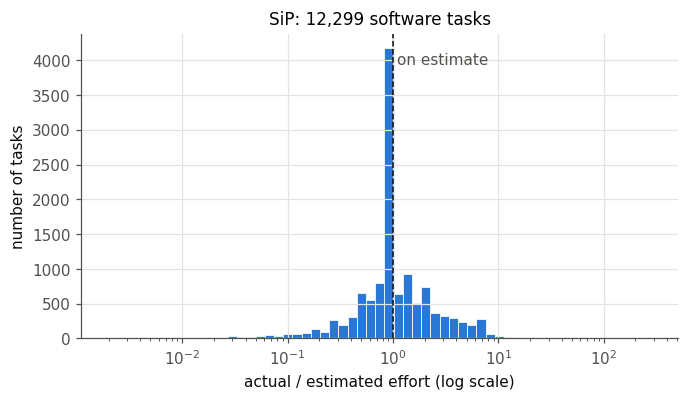

In [4]:
# Distribution of the ratios (log scale: a ratio of 10 is as far from 1 as a ratio of 0.1)
fig, ax = plt.subplots()
bins = np.logspace(np.log10(ratios.min()), np.log10(ratios.max()), 60)
ax.hist(ratios, bins=bins, color=BLUE, edgecolor="white", linewidth=0.5)
ax.set_xscale("log")
ax.axvline(1, color=INK, lw=1, ls="--")
ax.text(1.1, ax.get_ylim()[1] * 0.9, "on estimate", color=MUTED)
ax.set(xlabel="actual / estimated effort (log scale)", ylabel="number of tasks",
       title="SiP: 12,299 software tasks")
plt.show()

**A typical estimate is right; the average one is not.** Half of the tasks take no longer than
estimated (median ratio 1), but the mean ratio is 1.8, because a few tasks take 10 to 280 times their
estimate. Two effects therefore push projects late:

1. **the structure of the plan** (1.1): parallel paths make the maximum larger than the plan, even with
   unbiased estimates. This is Parts 2 to 4;
2. **the heavy tail of real overruns**: rare, huge delays. They also make Monte Carlo itself harder,
   which is Part 5.

---
## 2. Mathematical foundations

### 2.1 A project is a longest path

A project is a directed acyclic graph of $k$ tasks with random durations $D_1, \dots, D_k \ge 0$.
A task starts when all its predecessors are finished, so its finish time is
$$
F_j = D_j + \max_{i \in \mathrm{pred}(j)} F_i \qquad (F_j = D_j \text{ if } j \text{ has no predecessor}).
$$
Unrolling the recursion, the project duration is the length of the longest path:
$$
T = g(D) := \max_{P \in \mathcal P} L_P(D), \qquad L_P(D) = \sum_{i \in P} D_i ,
$$
where $\mathcal P$ is the set of paths from a first task to a last task. The classical PERT method
replaces each duration by its mean: $T_{\mathrm{PERT}} = g(\mathbb E[D])$.

### 2.2 The plan is optimistic

**Proposition 1.** $\mathbb E[T] \ge T_{\mathrm{PERT}}$, whatever the law of the durations.

*Proof.* For every path $P$, $T \ge L_P(D)$, so $\mathbb E[T] \ge \mathbb E[L_P(D)] = L_P(\mathbb E[D])$
by linearity. Taking the maximum over $P$ gives $\mathbb E[T] \ge \max_P L_P(\mathbb E[D]) = T_{\mathrm{PERT}}$. $\square$

This is Jensen's inequality for the convex function $g$ (a maximum of linear functions). The gap is
zero only if one path is almost surely the longest: **the delay comes from paths competing**.

### 2.3 Two parallel paths in closed form

**Proposition 2 (Clark, 1961).** Let $(X_1, X_2)$ be Gaussian with means $\mu_1, \mu_2$, standard
deviations $\sigma_1, \sigma_2$ and correlation $\rho$. Let
$\theta = \sqrt{\sigma_1^2 + \sigma_2^2 - 2\rho\sigma_1\sigma_2} > 0$ and $\alpha = (\mu_1 - \mu_2)/\theta$. Then
$$
\mathbb E[\max(X_1, X_2)] = \mu_1 \Phi(\alpha) + \mu_2 \Phi(-\alpha) + \theta\, \varphi(\alpha).
$$

*Proof.* $\max(X_1, X_2) = X_2 + (X_1 - X_2)^+$ and $Y = X_1 - X_2 \sim \mathcal N(\mu_1 - \mu_2, \theta^2)$.
Write $Y = a + \theta Z$ with $a = \mu_1 - \mu_2$ and $Z \sim \mathcal N(0, 1)$. Since
$\mathbb E[Z \mathbf 1\{Z > c\}] = \varphi(c)$,
$$
\mathbb E[Y^+] = \mathbb E[(a + \theta Z)\mathbf 1\{Z > -\alpha\}] = a\,\Phi(\alpha) + \theta\,\varphi(\alpha).
$$
Hence $\mathbb E[\max] = \mu_2 + (\mu_1 - \mu_2)\Phi(\alpha) + \theta\varphi(\alpha)$, which is the formula because $1 - \Phi(\alpha) = \Phi(-\alpha)$. $\square$

**Corollary.** If $\mu_1 = \mu_2 = \mu$, then $\mathbb E[\max] = \mu + \theta / \sqrt{2\pi}$: two paths that are
on time on average give a project that is late on average, by an amount proportional to the uncertainty $\theta$.

### 2.4 In general there is no formula

For a real network, computing $P(T \le t)$, or even $\mathbb E[T]$, is **#P-hard**, already when each
duration takes only two values (Hagstrom, 1988). The number of paths can grow exponentially with $k$,
and paths sharing tasks are correlated. Analytic shortcuts such as applying Clark's formula at every
merge (Sculli, 1983) must ignore these correlations; Section 3.5 measures the error this causes.
We therefore **simulate**.

### 2.5 The Monte Carlo estimator

Draw i.i.d. scenarios $D^{(1)}, \dots, D^{(n)}$ and compute $T^{(s)} = g(D^{(s)})$. We estimate

| quantity | estimator |
|---|---|
| expected duration $\mu = \mathbb E[T]$ | $\hat\mu_n = \frac1n \sum_s T^{(s)}$ |
| probability of being on time $p = P(T \le t)$ | $\hat p_n = \frac1n \sum_s \mathbf 1\{T^{(s)} \le t\}$ |
| date met with probability $q$ (e.g. the 90% date) $\xi_q$ | empirical $q$-quantile of the $T^{(s)}$ |

**Proposition 3.** $\hat\mu_n$ is unbiased and $\hat\mu_n \to \mu$ almost surely (law of large numbers).
If $\sigma^2 = \mathrm{Var}(T) < \infty$, then $\sqrt n\,(\hat\mu_n - \mu) \to \mathcal N(0, \sigma^2)$ (CLT), which gives
the asymptotic 95% interval $\hat\mu_n \pm 1.96\, \hat\sigma_n / \sqrt n$.

The error depends on $n$ and $\sigma$ only, **not on the number of tasks $k$**: only the cost of one
simulation grows, linearly in $k$ plus the number of precedence arcs. A grid over the $k$ durations
would need $N^k$ points instead.

### 2.6 Error bars with guarantees

**Proposition 4 (Hoeffding interval for the probability of being on time).** For every $n$ and $\delta \in (0, 1)$,
$$
P\big(|\hat p_n - p| \ge \varepsilon_n\big) \le \delta, \qquad \varepsilon_n = \sqrt{\frac{\ln(2/\delta)}{2n}} .
$$

*Proof.* The indicators $\mathbf 1\{T^{(s)} \le t\}$ are i.i.d. with values in $[0, 1]$ and mean $p$.
Hoeffding's inequality gives $P(|\hat p_n - p| \ge \varepsilon) \le 2e^{-2n\varepsilon^2}$. Setting the right-hand side equal to $\delta$ gives $\varepsilon_n$. $\square$

This interval holds for every $n$ (not only asymptotically) and for every law of the durations,
heavy tails included. For example, $\pm 1\%$ at 95% requires $n \ge \ln(40) / (2 \cdot 10^{-4}) \approx 18{,}445$ simulations.

**Proposition 5 (interval for a quantile).** Assume $T$ has a continuous distribution, and let
$T_{(1)} \le \dots \le T_{(n)}$ be the sorted sample and $N = \#\{s : T^{(s)} \le \xi_q\} \sim \mathrm{Bin}(n, q)$.
For ranks $l < u$,
$$
P\big(T_{(l)} \le \xi_q < T_{(u)}\big) = P(l \le N \le u - 1).
$$

*Proof.* $T_{(l)} \le \xi_q$ if and only if at least $l$ samples are $\le \xi_q$, i.e. $N \ge l$, and
$\xi_q < T_{(u)}$ if and only if $N \le u - 1$. $\square$

Choosing $l$ and $u$ from binomial quantiles makes this probability at least $1 - \delta$. Again **no
moment assumption** is needed. Finally, the Dvoretzky-Kiefer-Wolfowitz inequality (with Massart's
constant) gives a band around the whole CDF: $P\big(\sup_t |\hat F_n(t) - F(t)| > \varepsilon\big) \le 2 e^{-2n\varepsilon^2}$,
the same radius as Hoeffding, but valid for all deadlines $t$ at once.

### 2.7 Variance reduction

Every model in `mcpert` draws durations by inverse transform, $D_i = F_i^{-1}(U_i)$ with $U$ uniform on
$[0,1]^k$, so $T = h(U)$ where $h$ is nondecreasing in each coordinate ($g$ and every $F_i^{-1}$ are nondecreasing).

**Proposition 6 (antithetic variables).** $\mathrm{Cov}\big(h(U), h(\mathbf 1 - U)\big) \le 0$. Consequently
$$
\mathrm{Var}\Big(\tfrac{h(U) + h(\mathbf 1 - U)}{2}\Big) \le \tfrac12\,\mathrm{Var}(T):
$$
one antithetic pair is at least as precise as two independent simulations.

*Proof for $k = 1$.* Let $a(u) = h(u)$, nondecreasing, and $b(u) = h(1 - u)$, nonincreasing. For $U, V$
independent uniforms, $(a(U) - a(V))(b(U) - b(V)) \le 0$ since the two factors have opposite signs.
Taking expectations, $2\,\mathbb E[a(U)b(U)] - 2\,\mathbb E[a(U)]\,\mathbb E[b(U)] \le 0$, i.e.
$\mathrm{Cov}(a(U), b(U)) \le 0$. For $k > 1$ the same holds by induction over the coordinates
(Harris inequality; Esary, Proschan & Walkup, 1967). Finally
$\mathrm{Var}\big(\tfrac{A + B}{2}\big) = \tfrac14(\mathrm{Var} A + \mathrm{Var} B + 2\,\mathrm{Cov}(A, B)) \le \tfrac12 \mathrm{Var}(T)$. $\square$

**Proposition 7 (control variate).** Let $C$ be a variable with known mean. For every $\beta$,
$\hat\mu_\beta = \overline T - \beta(\overline C - \mathbb E[C])$ is unbiased, and its variance is minimal for
$\beta^* = \mathrm{Cov}(T, C) / \mathrm{Var}(C)$, where it equals $(1 - \rho^2)\,\mathrm{Var}(T)/n$ with $\rho = \mathrm{corr}(T, C)$.

*Proof.* $\mathrm{Var}(T - \beta C) = \mathrm{Var}\,T - 2\beta\,\mathrm{Cov}(T, C) + \beta^2\, \mathrm{Var}\,C$ is a
quadratic in $\beta$, minimal at $\beta^*$, with minimum $\mathrm{Var}\,T - \mathrm{Cov}(T, C)^2/\mathrm{Var}\,C = (1 - \rho^2)\,\mathrm{Var}\,T$. $\square$

We take $C$ = length of the PERT critical path $P^*$: $\mathbb E[C] = \sum_{i \in P^*} \mathbb E[D_i]$ is known
exactly, and $C$ is strongly correlated with $T$ because $P^*$ is often the longest path.

Parts 4 and 5 add two results: the criticality index of a task is a derivative of $\mathbb E[T]$ (Part 4), and
heavy tails break the CLT but not Propositions 4 and 5 (Part 5).

---
## 3. Implementation and validation

### 3.1 Code organisation

The simulation code is a small package, `mcpert`, next to this notebook:

| module | content |
|---|---|
| `network.py` | `Project`: the task graph, longest path for $n$ scenarios at once, critical path |
| `durations.py` | duration models by inverse transform: `Normal`, `Triangular`, `BetaPERT`, `EmpiricalRatio` (resampled SiP ratios) |
| `montecarlo.py` | `simulate` (with antithetic option), intervals `mean_ci`, `prob_ci`, `quantile_ci`, `dkw_radius`, `control_variate`, `coverage` |
| `clark.py` | Clark's formula, Sculli's approximation |
| `psplib.py`, `criticality.py` | Part 4: real-size networks, criticality index |
| `tails.py` | Part 5: Pareto model, Hill estimator, importance sampling |

### 3.2 Running example

A 7-task software project. Each task has a three-point estimate (optimistic $a$, most likely $m$,
pessimistic $b$) and follows the classical Beta-PERT law, whose mean is $(a + 4m + b)/6$.

```
spec ──┬── backend ──┐
       ├── frontend ─┼── integration ──┐
       ├── database ─┘                 ├── release
       └── docs ───────────────────────┘
```

In [5]:
# The running example
project, pert_model = software_release()

tasks = pd.DataFrame({
    "a": pert_model.a, "m": pert_model.m, "b": pert_model.b,
    "mean": pert_model.mean(), "std": np.sqrt(pert_model.var()),
    "after": [", ".join(project.names[i] for i in p) or "-" for p in project.predecessors],
}, index=project.names)
display(tasks.style.format(precision=2))

print("plan with most likely durations :", project.planned_duration(), "days")
print("PERT date (mean durations)      :", mc.pert_duration(project, pert_model), "days")
print("PERT critical path              :", [project.names[i] for i in project.critical_path(pert_model.mean())])

,a,m,b,mean,std,after
spec,3.00,5.00,9.00,5.33,1.11,-
backend,7.00,10.00,20.00,11.17,2.29,spec
frontend,6.00,9.00,18.00,10.00,2.14,spec
database,4.00,6.00,12.00,6.67,1.43,spec
docs,2.00,4.00,8.00,4.33,1.11,spec
integration,3.00,5.00,12.00,5.83,1.58,"backend, frontend, database"
release,1.00,1.00,2.00,1.17,0.14,"docs, integration"


plan with most likely durations : 21.0 days
PERT date (mean durations)      : 23.5 days
PERT critical path              : ['spec', 'backend', 'integration', 'release']


### 3.3 The forward pass, step by step

`Project.completion_time` visits the tasks once in topological order (every task after its
predecessors) and applies $F_j = D_j + \max_{i \in \mathrm{pred}(j)} F_i$. Below, the same computation for a single
scenario, written as a plain loop.

In [6]:
# Longest path of ONE scenario, by hand

# 1. Draw one scenario of the 7 durations.
d = pert_model.sample(1, rng=SEED)[0]

# 2. A task starts when its last predecessor ends.
finish = {}
for j in project.order:
    start = max((finish[i] for i in project.predecessors[j]), default=0.0)
    finish[j] = start + d[j]
    print(f"{project.names[j]:12s} starts {start:6.2f}   lasts {d[j]:5.2f}   ends {finish[j]:6.2f}")

# 3. The project ends with its last task. Compare with the package.
print(f"\nT by hand: {max(finish.values()):.4f}    T from mcpert: {project.completion_time(d)[0]:.4f}")

spec         starts   0.00   lasts  6.21   ends   6.21
docs         starts   6.21   lasts  3.94   ends  10.15
database     starts   6.21   lasts  6.28   ends  12.49
frontend     starts   6.21   lasts  8.46   ends  14.67
backend      starts   6.21   lasts 12.78   ends  18.99
integration  starts  18.99   lasts  5.12   ends  24.12
release      starts  24.12   lasts  1.12   ends  25.23

T by hand: 25.2327    T from mcpert: 25.2327


In [7]:
# The package does the same loop, but each step handles all n scenarios at once (a NumPy column).
import time

start = time.perf_counter()
T = mc.simulate(project, pert_model, n=100_000, rng=SEED)
print(f"100,000 simulations in {time.perf_counter() - start:.2f} s, E[T] ~ {T.mean():.2f} days")

100,000 simulations in 0.02 s, E[T] ~ 24.26 days


### 3.4 Validation against an exact formula

Two parallel tasks with Gaussian durations: $\mathbb E[T]$ is given by Clark's formula (Proposition 2).
One interval missing the truth proves little (a 95% interval misses 5% of the time), so we repeat the
experiment and look at the standardised errors $z = (\hat\mu_n - \mu) / (\hat\sigma_n / \sqrt n)$,
which should behave like $\mathcal N(0, 1)$.

In [8]:
# Parameters of the experiment
mu = np.array([10.0, 10.5])      # mean durations of the two tasks
sigma = np.array([2.0, 3.0])     # standard deviations
n, repetitions = 20_000, 200

In [9]:
# Monte Carlo versus Clark's exact formula

# 1. Exact value.
two_tasks = mc.Project([0, 0], [[], []])          # two tasks, no precedence: T = max(D1, D2)
exact_mean, _ = mc.clark_max(mu[0], sigma[0], mu[1], sigma[1])

# 2. Repeat the Monte Carlo estimate and standardise its error.
normal_model = mc.Normal(mu, sigma)
z = []
for rep in range(repetitions):
    est = mc.mean_ci(mc.simulate(two_tasks, normal_model, n, rng=rep))
    z.append((est.value - exact_mean) / (est.radius / 1.96))
z = np.array(z)

# 3. Compare with N(0, 1).
print(f"Clark (exact)              : {exact_mean:.4f}")
print(f"mean of z  (target 0)      : {z.mean():.3f}")
print(f"std of z   (target 1)      : {z.std():.3f}")
print(f"coverage   (target 0.95)   : {(np.abs(z) < 1.96).mean():.3f}")

Clark (exact)              : 11.7022
mean of z  (target 0)      : -0.042
std of z   (target 1)      : 0.951
coverage   (target 0.95)   : 0.955


**The simulator agrees with the exact formula.** The standardised errors are centred, with unit
variance, and the intervals cover the exact value about 95% of the time.

### 3.5 An analytic shortcut is biased

For a whole network, Sculli (1983) applies Clark's formula at every merge and treats the merging paths
as independent. In our example they are not: backend, frontend and database all start when spec ends.
With Gaussian durations of the same mean and variance as the Beta-PERT ones:

In [10]:
# Sculli's approximation versus Monte Carlo (Gaussian durations)
mu, sigma = pert_model.mean(), np.sqrt(pert_model.var())
approx_mean, approx_sd = mc.sculli(project, mu, sigma)
T = mc.simulate(project, mc.Normal(mu, sigma), n=200_000, rng=SEED)
est = mc.mean_ci(T)

display(pd.DataFrame({
    "E[T]": [approx_mean, est.value], "std of T": [approx_sd, T.std()],
    "95% interval for E[T]": ["-", est.interval],
}, index=["Sculli (independence assumed)", "Monte Carlo"]).style.format(precision=3))
print(f"bias of the approximation: {approx_mean - est.value:+.3f} days, "
      f"about {(approx_mean - est.value) / (est.radius / 1.96):.0f} Monte Carlo standard errors")

,E[T],std of T,95% interval for E[T]
Sculli (independence assumed),24.418,2.595,-
Monte Carlo,24.259,2.694,"[24.25, 24.27]"


bias of the approximation: +0.159 days, about 26 Monte Carlo standard errors


**Ignoring correlations overestimates the delay.** Paths that share a task are positively
correlated, and the maximum of positively correlated variables is smaller than the maximum of
independent ones with the same laws. The bias is small here, but it is far outside the Monte Carlo
error bars, and nothing in the formula warns about it.

### 3.6 The error decreases like $1/\sqrt n$

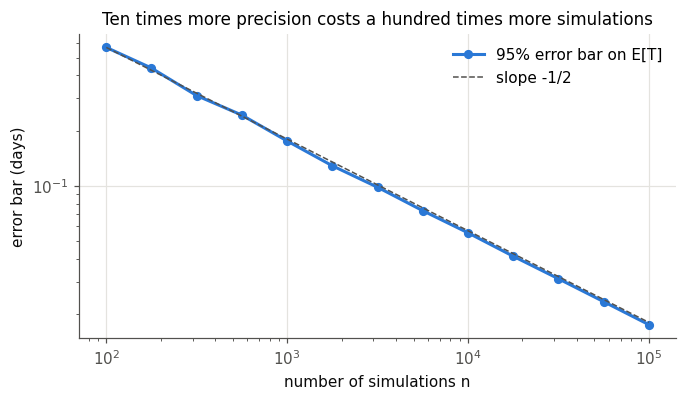

In [11]:
# Width of the 95% CLT interval for E[T] as n grows
sizes = np.logspace(2, 5, 13).astype(int)
radii = [mc.mean_ci(mc.simulate(project, pert_model, n, rng=SEED + i)).radius
         for i, n in enumerate(sizes)]

fig, ax = plt.subplots()
ax.loglog(sizes, radii, "o-", color=BLUE, ms=5, label="95% error bar on E[T]")
ax.loglog(sizes, radii[0] * np.sqrt(sizes[0] / sizes), "--", color=MUTED, lw=1, label="slope -1/2")
ax.set(xlabel="number of simulations n", ylabel="error bar (days)",
       title="Ten times more precision costs a hundred times more simulations")
ax.legend()
plt.show()

### 3.7 Coverage experiment

Do the 95% intervals of Section 2.6 really contain the true value 95% of the time? We repeat a small
study of $n = 500$ simulations 1,000 times. The "true" values come from one run of 2,000,000 simulations.

In [12]:
# Parameters of the experiment
n, repetitions = 500, 1_000
deadline = 25                     # days: P(T <= 25) is the probability of being on time

In [13]:
# Empirical coverage of four 95% intervals

# 1. Reference values from a very large run.
T_ref = mc.simulate(project, pert_model, n=2_000_000, rng=1)
true_mean, true_p, true_q90 = T_ref.mean(), (T_ref <= deadline).mean(), np.quantile(T_ref, 0.9)

# 2. Repeat a small study and count how often each interval contains the truth.
small_study = lambda rng: mc.simulate(project, pert_model, n, rng=rng)
coverage = pd.Series({
    "CLT, E[T]": mc.coverage(small_study, mc.mean_ci, true_mean, repetitions, rng=SEED),
    "Hoeffding, P(on time)": mc.coverage(small_study, lambda T: mc.prob_ci(T <= deadline),
                                         true_p, repetitions, rng=SEED),
    "CLT, P(on time)": mc.coverage(small_study, lambda T: mc.prob_ci(T <= deadline, method="clt"),
                                   true_p, repetitions, rng=SEED),
    "order statistics, 90% date": mc.coverage(small_study, lambda T: mc.quantile_ci(T, 0.9),
                                              true_q90, repetitions, rng=SEED),
}, name="coverage (target 95%)")
display(coverage.to_frame().style.format("{:.1%}"))

,coverage (target 95%)
"CLT, E[T]",94.5%
"Hoeffding, P(on time)",99.5%
"CLT, P(on time)",94.3%
"order statistics, 90% date",96.0%


**All four intervals keep their promise here.** Hoeffding over-covers: it holds for every $n$ and
every distribution, so it is conservative. The CLT intervals are close to 95% because Beta-PERT
durations are bounded. Part 5 repeats this experiment with heavy-tailed delays.

### 3.8 Variance reduction in practice

In [14]:
# Same budget (n = 20,000 longest-path evaluations), three estimators of E[T]
n = 20_000

# 1. Plain Monte Carlo and antithetic pairs.
plain = mc.mean_ci(mc.simulate(project, pert_model, n, rng=SEED))
antithetic = mc.mean_ci(mc.simulate(project, pert_model, n, rng=SEED, antithetic=True))

# 2. Control variate: length of the PERT critical path, whose mean is known exactly.
T, D = mc.simulate(project, pert_model, n, rng=SEED, return_durations=True)
path = project.critical_path(pert_model.mean())
controlled, beta, rho = mc.control_variate(T, D[:, path].sum(axis=1), pert_model.mean()[path].sum())

# 3. Compare the error bars. Variance reduction factor = (plain radius / radius)^2.
results = pd.DataFrame({
    "estimate of E[T]": [e.value for e in (plain, antithetic, controlled)],
    "95% error bar": [e.radius for e in (plain, antithetic, controlled)],
}, index=["plain Monte Carlo", "antithetic", "control variate"])
results["variance reduction factor"] = (plain.radius / results["95% error bar"]) ** 2
display(results.style.format(precision=3))
print(f"corr(T, PERT path length) = {rho:.3f}, so Proposition 7 predicts a factor 1/(1 - rho^2) = {1 / (1 - rho**2):.2f}")

,estimate of E[T],95% error bar,variance reduction factor
plain Monte Carlo,24.272,0.039,1.000
antithetic,24.269,0.020,3.977
control variate,24.281,0.018,4.595


corr(T, PERT path length) = 0.885, so Proposition 7 predicts a factor 1/(1 - rho^2) = 4.59


**Both methods divide the cost by about four.** The control variate gains exactly the factor
$1/(1-\rho^2)$ predicted by Proposition 7. The antithetic gain is similar to the one Sullivan, Hayya & Schaul
(1982) report on random networks: the same precision with about a quarter of the simulations.

### Summary of Parts 1-3

* The plan is optimistic by construction (Proposition 1), even with unbiased estimates.
* No formula exists in general, but Monte Carlo gives the delivery date with an error of order
  $\sigma/\sqrt n$, independent of the number of tasks, and the simulator matches the exact formula.
* Hoeffding and order statistics give error bars that need no assumption on the durations.
  Antithetic variables and a control variate each divide the cost by about four.

Part 4 applies these tools to realistic projects.